In [1]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATASET_DIR = Path(r"D:\soilDatasets\dataset_v3")

print("Dataset directory:", DATASET_DIR)
print("Exists:", DATASET_DIR.exists())

Dataset directory: D:\soilDatasets\dataset_v3
Exists: True


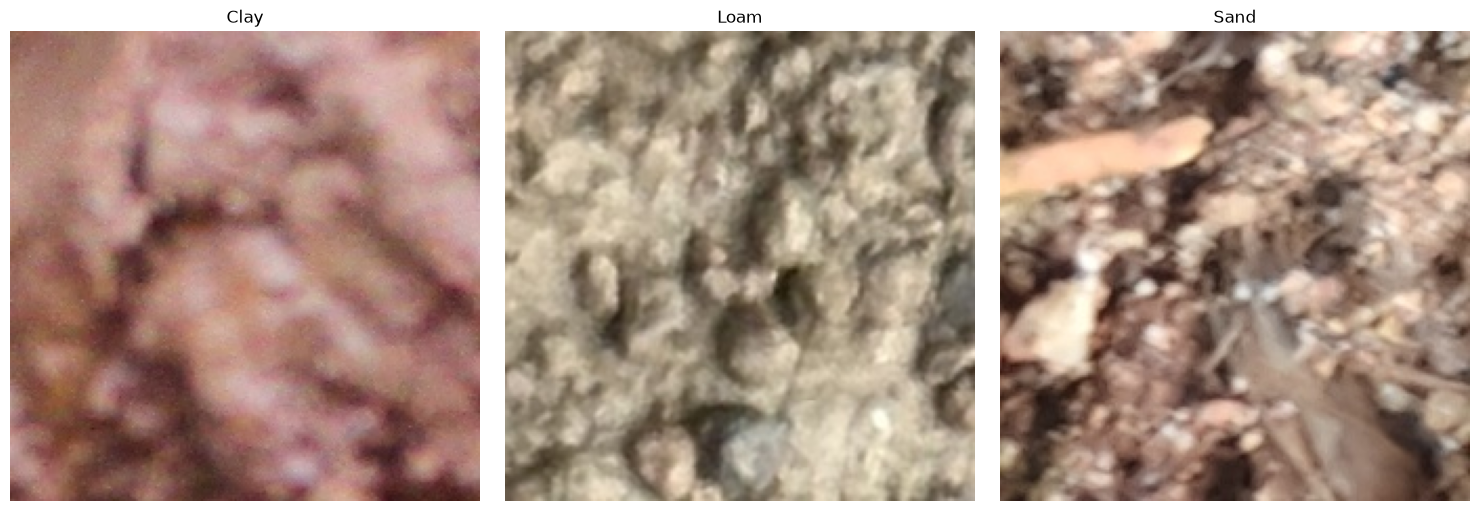

In [2]:
import random
from PIL import Image
import matplotlib.pyplot as plt

classes = ["Clay", "Loam", "Sand"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, soil_class in zip(axes, classes):
    class_dir = DATASET_DIR / "train" / soil_class
    image_path = random.choice(list(class_dir.glob("*.jpg")))
    
    image = Image.open(image_path)
    
    ax.imshow(image)
    ax.set_title(soil_class)
    ax.axis("off")

plt.tight_layout()
plt.show()

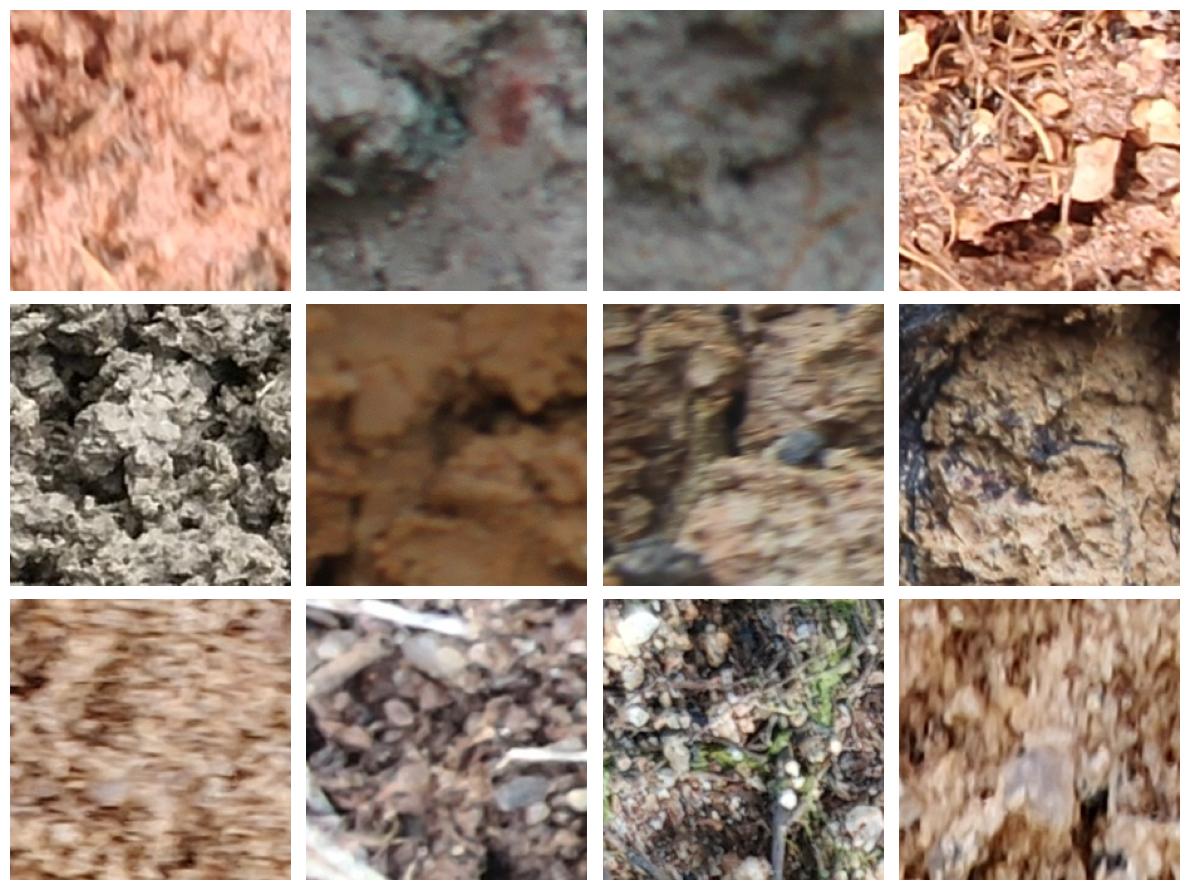

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for row, soil_class in enumerate(classes):
    class_dir = DATASET_DIR / "train" / soil_class
    image_paths = random.sample(list(class_dir.glob("*.jpg")), 4)

    for col, image_path in enumerate(image_paths):
        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                soil_class,
                fontsize=14,
                rotation=90
            )

plt.tight_layout()
plt.show()

In [4]:
from pathlib import Path
from PIL import Image

splits = ["train", "val", "test"]
classes = ["Clay", "Loam", "Sand"]

print("DATASET QUALITY CHECK")
print("=" * 50)

total_images = 0

for split in splits:
    print(f"\n{split.upper()}")

    for soil_class in classes:
        folder = DATASET_DIR / split / soil_class
        images = list(folder.glob("*.jpg"))

        valid = 0
        corrupted = 0

        for image_path in images:
            try:
                with Image.open(image_path) as img:
                    img.verify()
                valid += 1
            except Exception:
                corrupted += 1

        print(
            f"{soil_class:5} | "
            f"Total: {len(images):6} | "
            f"Valid: {valid:6} | "
            f"Corrupt: {corrupted:3}"
        )

        total_images += len(images)

print("\n" + "=" * 50)
print("TOTAL IMAGES:", total_images)

DATASET QUALITY CHECK

TRAIN
Clay  | Total:  24623 | Valid:  24623 | Corrupt:   0
Loam  | Total:  29082 | Valid:  29082 | Corrupt:   0
Sand  | Total:  16528 | Valid:  16528 | Corrupt:   0

VAL
Clay  | Total:   2012 | Valid:   2012 | Corrupt:   0
Loam  | Total:   6317 | Valid:   6317 | Corrupt:   0
Sand  | Total:   2400 | Valid:   2400 | Corrupt:   0

TEST
Clay  | Total:   2352 | Valid:   2352 | Corrupt:   0
Loam  | Total:   6336 | Valid:   6336 | Corrupt:   0
Sand  | Total:   2400 | Valid:   2400 | Corrupt:   0

TOTAL IMAGES: 92050


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

data = []

for split in ["train", "val", "test"]:
    for soil_class in ["Clay", "Loam", "Sand"]:
        folder = DATASET_DIR / split / soil_class
        count = len(list(folder.glob("*.jpg")))

        data.append({
            "Split": split,
            "Class": soil_class,
            "Count": count
        })

df = pd.DataFrame(data)

display(df)

,Split,Class,Count
0,train,Clay,24623
1,train,Loam,29082
2,train,Sand,16528
3,val,Clay,2012
4,val,Loam,6317
5,val,Sand,2400
6,test,Clay,2352
7,test,Loam,6336
8,test,Sand,2400


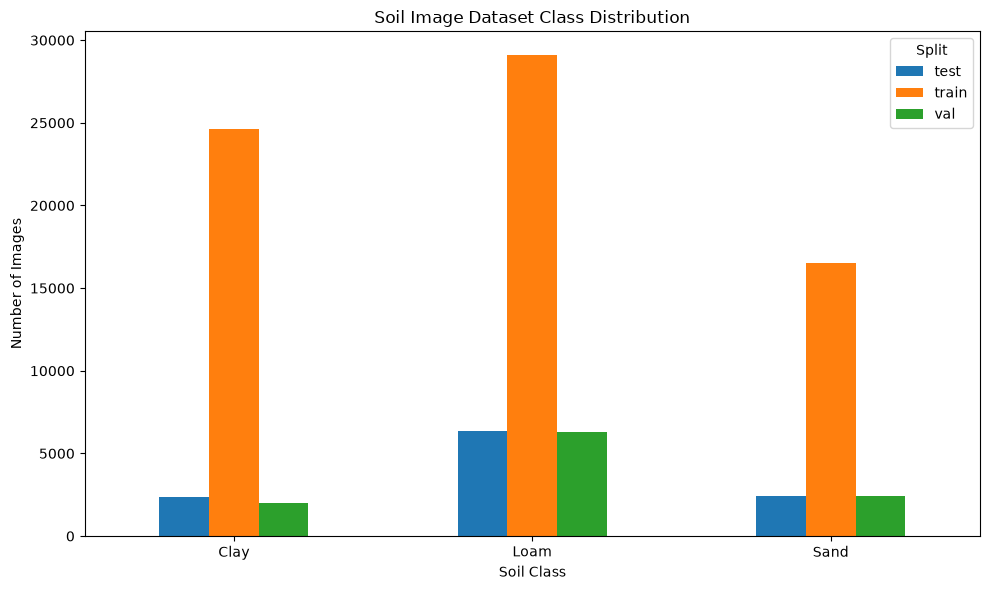

In [8]:
distribution = df.pivot(
    index="Class",
    columns="Split",
    values="Count"
)

distribution.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Soil Image Dataset Class Distribution")
plt.xlabel("Soil Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
import pandas as pd

# Dataset splits and class mapping
splits = ["train", "val", "test"]

class_mapping = {
    "Clay": 0,
    "Loam": 1,
    "Sand": 2
}

records = []

for split in splits:
    for soil_class, class_id in class_mapping.items():

        class_dir = DATASET_DIR / split / soil_class

        for image_path in class_dir.glob("*.jpg"):
            records.append({
                "image_path": str(image_path),
                "split": split,
                "soil_class": soil_class,
                "class_id": class_id
            })

manifest_df = pd.DataFrame(records)

print("Total records:", len(manifest_df))
display(manifest_df.head())

Total records: 92050


,image_path,split,soil_class,class_id
0,D:\SoilDatasets\dataset_v3\train\Clay\123b8529...,train,Clay,0
1,D:\SoilDatasets\dataset_v3\train\Clay\123b8529...,train,Clay,0
2,D:\SoilDatasets\dataset_v3\train\Clay\123b8529...,train,Clay,0
3,D:\SoilDatasets\dataset_v3\train\Clay\123b8529...,train,Clay,0
4,D:\SoilDatasets\dataset_v3\train\Clay\123b8529...,train,Clay,0


In [10]:
print("Records by split:")
display(
    manifest_df.groupby(["split", "soil_class"])
    .size()
    .reset_index(name="count")
)

print("\nClass mapping:")
print(class_mapping)

Records by split:


,split,soil_class,count
0,test,Clay,2352
1,test,Loam,6336
2,test,Sand,2400
3,train,Clay,24623
4,train,Loam,29082
5,train,Sand,16528
6,val,Clay,2012
7,val,Loam,6317
8,val,Sand,2400



Class mapping:
{'Clay': 0, 'Loam': 1, 'Sand': 2}


In [11]:
MANIFEST_PATH = Path("../dataset/soil_image_manifest.csv")

manifest_df.to_csv(MANIFEST_PATH, index=False)

print("Manifest saved to:", MANIFEST_PATH.resolve())
print("File exists:", MANIFEST_PATH.exists())
print("File size (KB):", round(MANIFEST_PATH.stat().st_size / 1024, 2))

Manifest saved to: D:\J26-IT-433-Soil-Assessment\J26-IT-433-Soil-Assessment-Planner\component1\dataset\soil_image_manifest.csv
File exists: True
File size (KB): 6588.52


In [12]:
# Create portable image paths
manifest_df["image_path"] = manifest_df["image_path"].apply(
    lambda x: str(Path(x).relative_to(DATASET_DIR)).replace("\\", "/")
)

display(manifest_df.head())

,image_path,split,soil_class,class_id
0,train/Clay/123b85296021_0000.jpg,train,Clay,0
1,train/Clay/123b85296021_0001.jpg,train,Clay,0
2,train/Clay/123b85296021_0002.jpg,train,Clay,0
3,train/Clay/123b85296021_0003.jpg,train,Clay,0
4,train/Clay/123b85296021_0004.jpg,train,Clay,0


In [13]:
print(manifest_df["image_path"].head(10).tolist())

['train/Clay/123b85296021_0000.jpg', 'train/Clay/123b85296021_0001.jpg', 'train/Clay/123b85296021_0002.jpg', 'train/Clay/123b85296021_0003.jpg', 'train/Clay/123b85296021_0004.jpg', 'train/Clay/123b85296021_0005.jpg', 'train/Clay/123b85296021_0006.jpg', 'train/Clay/123b85296021_0007.jpg', 'train/Clay/123b85296021_0008.jpg', 'train/Clay/123b85296021_0009.jpg']


In [14]:
MANIFEST_PATH = Path("../dataset/soil_image_manifest.csv")

manifest_df.to_csv(MANIFEST_PATH, index=False)

print("Portable manifest saved successfully.")
print("Path:", MANIFEST_PATH.resolve())
print("Total records:", len(manifest_df))

Portable manifest saved successfully.
Path: D:\J26-IT-433-Soil-Assessment\J26-IT-433-Soil-Assessment-Planner\component1\dataset\soil_image_manifest.csv
Total records: 92050
